In [1]:
# ============================================================
# COMP9414 Assignment 1 – Solar Radiation Forecasting
# Student ID: z5565492
# ============================================================

import os, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from scipy import stats

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)

DATA_DIR = r"H:\CLASS\9414\ass1\COMP9414_Assignment_1_datasets\datasets"
DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HORIZONS = 7

print(f"PyTorch: {torch.__version__}  |  Device: {DEVICE}")




PyTorch: 2.0.1+cpu  |  Device: cpu



Part A: Data Preprocessing
Total rows: 6575, bad quality removed: 1005 (15.29%)


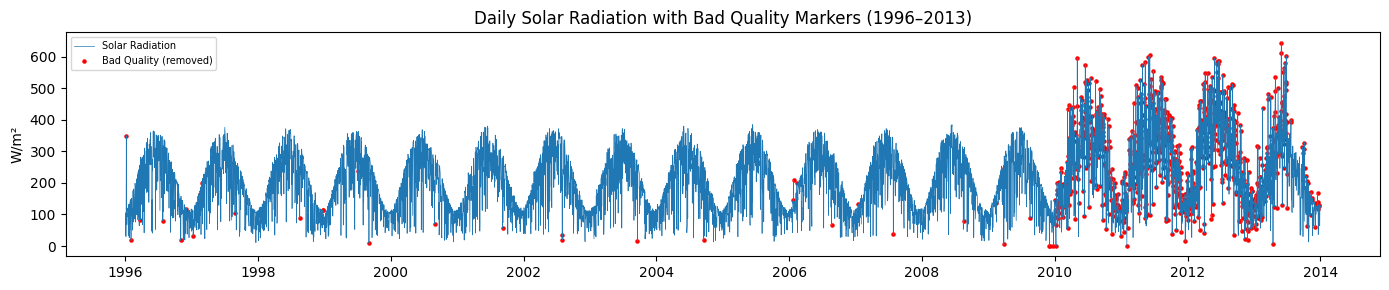

Rows after feature engineering: 5556
Train: 4711 (1996-01-09 ~ 2008-12-31)
Val:   484 (2009-01-08 ~ 2010-12-31)
Test:  347 (2011-01-26 ~ 2013-12-22)
Scaler saved.  Input dim: 13


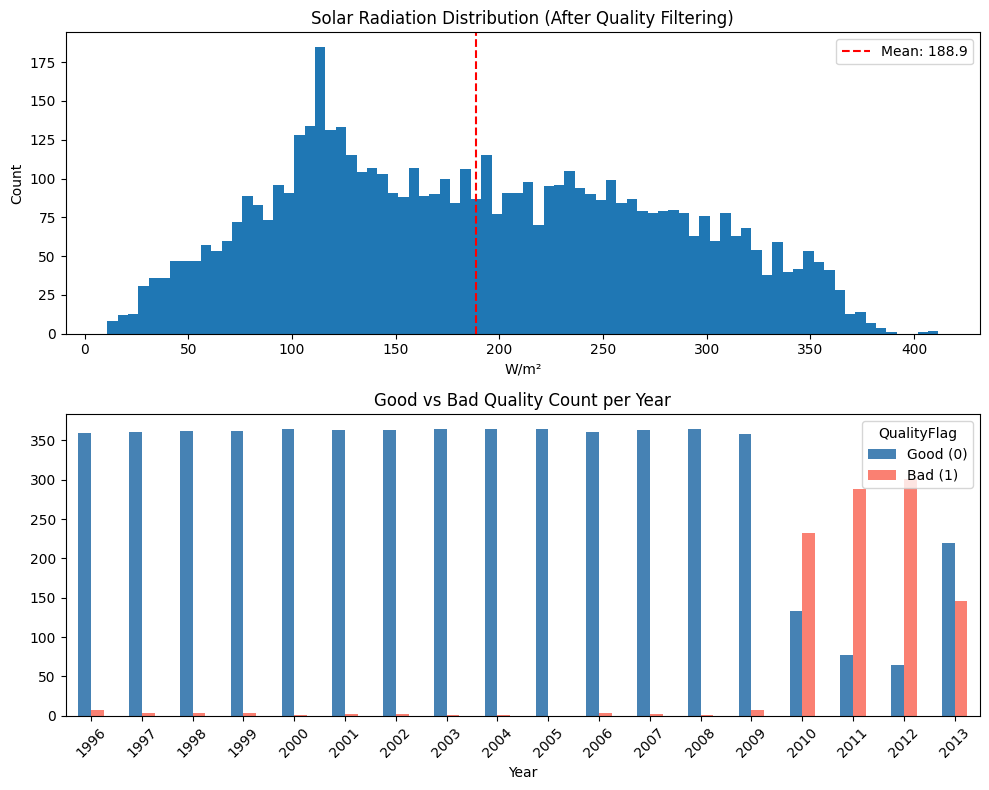

Part A complete.


In [2]:
# ══════════════════════════════════════════════════════════════
# PART A: Data Preprocessing
# ══════════════════════════════════════════════════════════════
print("\n" + "="*60 + "\nPart A: Data Preprocessing\n" + "="*60)

# 1. Load and clean
files = sorted([f for f in os.listdir(DATA_DIR) if f.endswith(".csv")])
dfs   = [pd.read_csv(os.path.join(DATA_DIR, f), parse_dates=["date"]) for f in files]
raw   = pd.concat(dfs, ignore_index=True).sort_values("date").reset_index(drop=True)
raw.rename(columns={"date": "TIMESTAMP", "solar_t": "SolarRadiation", "bad_quality": "QualityFlag"}, inplace=True)

n_total  = len(raw)
bad_mask = raw["QualityFlag"] == 1
print(f"Total rows: {n_total}, bad quality removed: {bad_mask.sum()} ({bad_mask.mean()*100:.2f}%)")

# Plot 1: time-series with bad quality markers
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(raw["TIMESTAMP"], raw["SolarRadiation"], lw=0.5, label="Solar Radiation")
ax.scatter(raw.loc[bad_mask, "TIMESTAMP"], raw.loc[bad_mask, "SolarRadiation"],
           c="red", s=5, label="Bad Quality (removed)")
ax.set_title("Daily Solar Radiation with Bad Quality Markers (1996–2013)")
ax.set_ylabel("W/m²"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("partA_timeseries.png", dpi=120); plt.show()

clean = raw[~bad_mask].copy().reset_index(drop=True)

# 2. Fourier encoding (leap-year aware)
clean["day_of_year"] = clean["TIMESTAMP"].dt.dayofyear
leap_denom = clean["TIMESTAMP"].dt.year.apply(
    lambda y: 366 if (y % 4 == 0 and (y % 100 != 0 or y % 400 == 0)) else 365)
clean["day_sin"] = np.sin(2 * np.pi * clean["day_of_year"] / leap_denom)
clean["day_cos"] = np.cos(2 * np.pi * clean["day_of_year"] / leap_denom)

# 3. Rolling statistics – requires exactly 7 preceding observations
sr = clean["SolarRadiation"]
clean["solar_mean_7d"] = sr.rolling(7, min_periods=7).mean()
clean["solar_std_7d"]  = sr.rolling(7, min_periods=7).std(ddof=1)
clean["solar_min_7d"]  = sr.rolling(7, min_periods=7).min()
clean["solar_max_7d"]  = sr.rolling(7, min_periods=7).max()

# 4. Lagged features (rows in filtered dataset, not calendar days)
for k in range(1, 8):
    clean[f"solar_lag_{k}"] = sr.shift(k)

# 5. Target variables
for h in range(1, 8):
    clean[f"solar_t+{h}"] = sr.shift(-h)

NON_LAG_COLS = ["day_sin", "day_cos",
                "solar_mean_7d", "solar_std_7d", "solar_min_7d", "solar_max_7d"]
LAG_COLS     = [f"solar_lag_{k}" for k in range(1, 8)]
FEATURE_COLS = NON_LAG_COLS + LAG_COLS       # non-lag first, then lag (needed for attention)
TARGET_COLS  = [f"solar_t+{h}" for h in range(1, 8)]
N_NON_LAG    = len(NON_LAG_COLS)             # 6
N_LAG        = len(LAG_COLS)                 # 7

clean = clean.dropna(subset=FEATURE_COLS + TARGET_COLS).reset_index(drop=True)
print(f"Rows after feature engineering: {len(clean)}")

# 6. Temporal split: train 1996-2008, val 2009-2010, test 2011-2013
# Drop first 7 rows at each partition boundary to avoid feature leakage
train_df = clean[clean["TIMESTAMP"].dt.year <= 2008].reset_index(drop=True)
val_df   = clean[(clean["TIMESTAMP"].dt.year >= 2009) &
                 (clean["TIMESTAMP"].dt.year <= 2010)].reset_index(drop=True).iloc[7:].reset_index(drop=True)
test_df  = clean[clean["TIMESTAMP"].dt.year >= 2011].reset_index(drop=True).iloc[7:].reset_index(drop=True)

print(f"Train: {len(train_df)} ({train_df['TIMESTAMP'].min().date()} ~ {train_df['TIMESTAMP'].max().date()})")
print(f"Val:   {len(val_df)} ({val_df['TIMESTAMP'].min().date()} ~ {val_df['TIMESTAMP'].max().date()})")
print(f"Test:  {len(test_df)} ({test_df['TIMESTAMP'].min().date()} ~ {test_df['TIMESTAMP'].max().date()})")

# Scale features – fit on train only, targets remain in original units
scaler = StandardScaler()
Xtr = scaler.fit_transform(train_df[FEATURE_COLS].values).astype(np.float32)
Xva = scaler.transform(val_df[FEATURE_COLS].values).astype(np.float32)
Xte = scaler.transform(test_df[FEATURE_COLS].values).astype(np.float32)
Ytr = train_df[TARGET_COLS].values.astype(np.float32)
Yva = val_df[TARGET_COLS].values.astype(np.float32)
Yte = test_df[TARGET_COLS].values.astype(np.float32)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print(f"Scaler saved.  Input dim: {Xtr.shape[1]}")

# Plot 2 & 3: distribution and quality counts
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].hist(clean["SolarRadiation"], bins=80)
axes[0].axvline(clean["SolarRadiation"].mean(), color="red", ls="--",
                label=f"Mean: {clean['SolarRadiation'].mean():.1f}")
axes[0].set_title("Solar Radiation Distribution (After Quality Filtering)")
axes[0].set_xlabel("W/m²"); axes[0].set_ylabel("Count"); axes[0].legend()

raw["Year"] = raw["TIMESTAMP"].dt.year
counts = raw.groupby(["Year", "QualityFlag"]).size().unstack(fill_value=0)
counts.rename(columns={0: "Good (0)", 1: "Bad (1)"}, inplace=True)
counts.plot(kind="bar", ax=axes[1], color=["steelblue", "salmon"])
axes[1].set_title("Good vs Bad Quality Count per Year")
axes[1].set_xlabel("Year"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("partA_distribution.png", dpi=120); plt.show()
print("Part A complete.")




In [3]:
# ══════════════════════════════════════════════════════════════
# Shared Utilities
# ══════════════════════════════════════════════════════════════
INPUT_DIM = Xtr.shape[1]   # 13

def make_loader(X, Y, batch_size=64, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(Y)),
                      batch_size=batch_size, shuffle=shuffle)

def compute_metrics(pred, Y):
    err  = pred - Y
    rmse = np.sqrt(np.mean(err**2, axis=0))
    mae  = np.mean(np.abs(err), axis=0)
    mbe  = np.mean(err, axis=0)
    p95  = np.percentile(np.abs(err), 95, axis=0)
    return rmse, mae, mbe, p95

def evaluate(model, X, Y, return_pred=False):
    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X).to(DEVICE)).cpu().numpy()
    m = compute_metrics(pred, Y)
    return (m, pred) if return_pred else m

def print_metrics(rmse, mae, mbe=None, p95=None):
    has_extra = mbe is not None and p95 is not None
    hdr = f"{'':5s}{'RMSE':>8s}{'MAE':>8s}" + (f"{'MBE':>8s}{'P95':>8s}" if has_extra else "")
    print(hdr)
    for h in range(HORIZONS):
        row = f"t+{h+1}  {rmse[h]:8.4f} {mae[h]:8.4f}"
        if has_extra: row += f" {mbe[h]:8.4f} {p95[h]:8.4f}"
        print(row)
    row = f"Macro {rmse.mean():8.4f} {mae.mean():8.4f}"
    if has_extra: row += f" {mbe.mean():8.4f} {p95.mean():8.4f}"
    print(row)

def train_model(model, train_loader, val_loader, loss_fn,
                lr=1e-3, max_epochs=300, patience=20):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_ep, best_state = float("inf"), 0, None
    t0 = time.time()
    hist_tr, hist_va = [], []
    for ep in range(1, max_epochs + 1):
        model.train(); tl = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            tl += loss.item() * len(xb)
        tl /= len(train_loader.dataset)
        model.eval(); vl = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                vl += loss_fn(model(xb), yb).item() * len(xb)
        vl /= len(val_loader.dataset)
        hist_tr.append(tl); hist_va.append(vl)
        if vl < best_val:
            best_val, best_ep = vl, ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if ep - best_ep >= patience:
            print(f"  Early stop @ epoch {ep}, best val: {best_val:.4f}")
            break
    model.load_state_dict(best_state)
    elapsed = time.time() - t0
    print(f"  Done, {elapsed:.1f}s")
    return hist_tr, hist_va, elapsed


# ── Model Architectures ──────────────────────────────────────

class MultiOutputMLP(nn.Module):
    """Single shared network → 7 outputs (Parts B, ablation baseline)."""
    def __init__(self, in_dim=INPUT_DIM, hidden=128, out_dim=HORIZONS, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, out_dim)
        )
    def forward(self, x): return self.net(x)

class SingleOutputMLP(nn.Module):
    """Shared architecture, single output (Part C individual models)."""
    def __init__(self, in_dim=INPUT_DIM, hidden=128, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1)
        )
    def forward(self, x): return self.net(x)

class MultiTaskMLP(nn.Module):
    """Shared encoder + per-horizon output heads with hidden layer (Strategy 3)."""
    def __init__(self, in_dim=INPUT_DIM, hidden=128, head_hidden=32,
                 horizons=HORIZONS, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        )
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden, head_hidden), nn.ReLU(), nn.Linear(head_hidden, 1))
            for _ in range(horizons)
        ])
    def forward(self, x):
        enc = self.encoder(x)
        return torch.cat([h(enc) for h in self.heads], dim=1)

class MCDropoutMLP(nn.Module):
    """Dropout-based uncertainty estimation – no BatchNorm."""
    def __init__(self, in_dim=INPUT_DIM, hidden=128, out_dim=HORIZONS, dropout=0.2):
        super().__init__()
        self.fc1  = nn.Linear(in_dim, hidden)
        self.fc2  = nn.Linear(hidden, hidden)
        self.fc3  = nn.Linear(hidden, out_dim)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        x = F.relu(self.drop(self.fc1(x)))
        x = F.relu(self.drop(self.fc2(x)))
        return self.fc3(x)
    def mc_predict(self, X, T=50, device=DEVICE):
        self.train()   # keep dropout active
        X_t = torch.tensor(X).to(device)
        with torch.no_grad():
            preds = torch.stack([self(X_t) for _ in range(T)])
        mu  = preds.mean(0).detach()
        sig = preds.std(0).detach()
        return mu, sig

class AttentionMLP(nn.Module):
    """Scaled dot-product attention over 7 lag features, concat with non-lag features."""
    def __init__(self, n_non_lag=N_NON_LAG, n_lags=N_LAG, dk=16,
                 hidden=128, out_dim=HORIZONS, dropout=0.2):
        super().__init__()
        self.n_non_lag = n_non_lag
        self.n_lags    = n_lags
        self.dk        = dk
        self.lag_proj  = nn.Linear(1, dk)
        self.q_proj    = nn.Linear(dk, dk)
        self.k_proj    = nn.Linear(dk, dk)
        self.v_proj    = nn.Linear(dk, dk)
        self.net = nn.Sequential(
            nn.Linear(n_non_lag + n_lags * dk, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, out_dim)
        )
    def forward(self, x, return_attn=False):
        non_lag  = x[:, :self.n_non_lag]
        lags_emb = self.lag_proj(x[:, self.n_non_lag:].unsqueeze(-1))  # (B, L, dk)
        Q = self.q_proj(lags_emb); K = self.k_proj(lags_emb); V = self.v_proj(lags_emb)
        attn_w   = torch.softmax(Q @ K.transpose(-2, -1) / self.dk**0.5, dim=-1)
        attn_out = (attn_w @ V).reshape(x.size(0), -1)
        out = self.net(torch.cat([non_lag, attn_out], dim=1))
        return (out, attn_w) if return_attn else out


# ── Loss Functions ───────────────────────────────────────────

def _weights():
    return torch.tensor([1.0 / (k**0.5) for k in range(1, HORIZONS+1)], device=DEVICE)

class WeightedMSE(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer("w", _weights())
    def forward(self, pred, target):
        return (((pred - target)**2) * self.w).mean()

class PseudoHuberLoss(nn.Module):
    def __init__(self, delta=50.0):
        super().__init__()
        self.delta = delta
        self.register_buffer("w", _weights())
    def forward(self, pred, target):
        d = self.delta; u = pred - target
        return (self.w * (d**2 * (torch.sqrt(1 + (u/d)**2) - 1))).mean()

class WeightedQuantileLoss(nn.Module):
    def __init__(self, tau=0.8):
        super().__init__()
        self.tau = tau
        self.register_buffer("w", _weights())
    def forward(self, pred, target):
        u = target - pred
        return (self.w * torch.max(self.tau * u, (self.tau - 1) * u)).mean()


train_loader = make_loader(Xtr, Ytr, shuffle=True)
val_loader   = make_loader(Xva, Yva)





Part B: Multi-Output Model + Custom Loss Functions

▶ Training [WeightedMSE]
  Early stop @ epoch 139, best val: 2170.9698
  Done, 38.2s
         RMSE     MAE     MBE     P95
t+1   57.6151  44.8968  -1.3538 125.1539
t+2   58.8262  45.8068  -2.4404 128.2431
t+3   60.0535  46.9975  -3.4052 135.6082
t+4   60.8517  47.4193  -3.1832 135.2830
t+5   62.2504  48.4578  -5.2890 136.0516
t+6   63.8719  49.4537  -3.2668 140.6023
t+7   65.3061  50.6093  -3.7563 145.9641
Macro  61.2536  47.6630  -3.2421 135.2723

▶ Training [PseudoHuber]
  Early stop @ epoch 50, best val: 664.6482
  Done, 13.1s
         RMSE     MAE     MBE     P95
t+1   58.3904  44.6651   4.7496 118.6621
t+2   58.8987  45.3761   3.7382 129.1855
t+3   59.7520  46.2337   2.1403 130.5957
t+4   60.9870  46.9057   3.4620 139.4552
t+5   62.5756  47.9042   3.9915 144.2933
t+6   64.2461  49.1511   3.1535 140.1216
t+7   65.3318  49.9969   2.2179 145.8589
Macro  61.4545  47.1761   3.3504 135.4532

▶ Training [QuantileLoss]
  Early stop @ ep

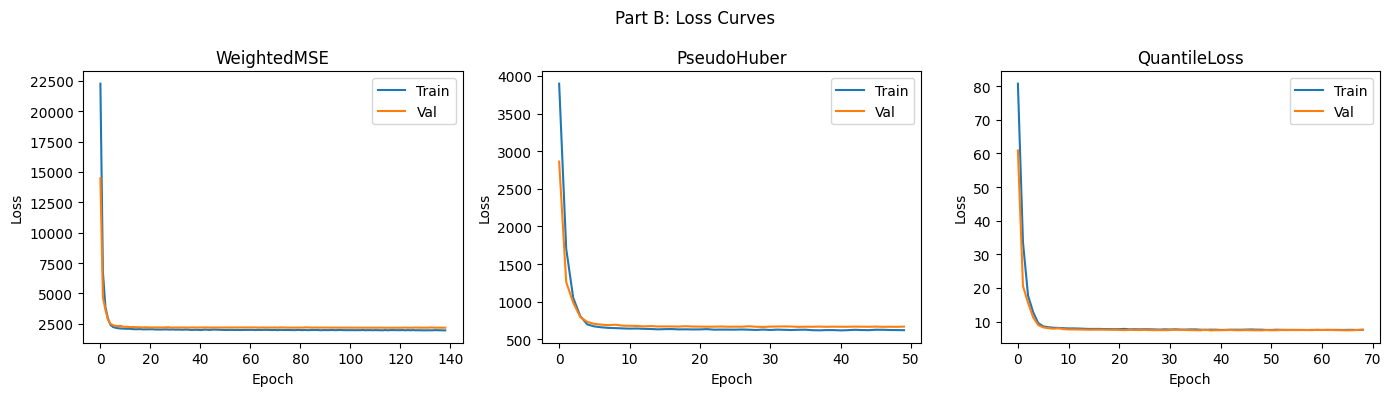

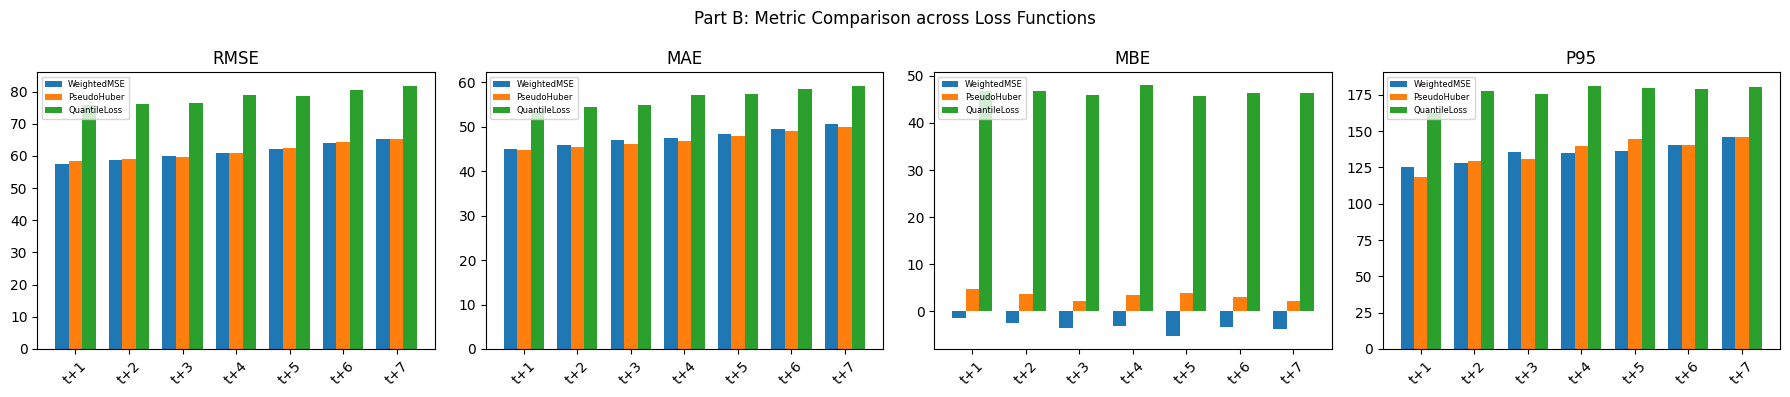


Part B Summary (Macro Average):
  WeightedMSE: RMSE=61.2536  MAE=47.6630  MBE=-3.2421  P95=135.2723
  PseudoHuber: RMSE=61.4545  MAE=47.1761  MBE=3.3504  P95=135.4532
  QuantileLoss: RMSE=78.3647  MAE=56.4727  MBE=46.5542  P95=176.7368


In [4]:
# ══════════════════════════════════════════════════════════════
# PART B: Multi-Output Model + Custom Loss Functions
# ══════════════════════════════════════════════════════════════
print("\n" + "="*60 + "\nPart B: Multi-Output Model + Custom Loss Functions\n" + "="*60)

loss_fns = {
    "WeightedMSE":  WeightedMSE(),
    "PseudoHuber":  PseudoHuberLoss(delta=50.0),
    "QuantileLoss": WeightedQuantileLoss(tau=0.8),
}

partB_models  = {}
partB_results = {}
partB_hist    = {}

for name, loss_fn in loss_fns.items():
    print(f"\n▶ Training [{name}]")
    torch.manual_seed(42)
    model = MultiOutputMLP().to(DEVICE)
    hist_tr, hist_va, _ = train_model(model, train_loader, val_loader, loss_fn)
    rmse, mae, mbe, p95 = evaluate(model, Xte, Yte)
    print_metrics(rmse, mae, mbe, p95)
    partB_models[name]  = model
    partB_results[name] = (rmse, mae, mbe, p95)
    partB_hist[name]    = (hist_tr, hist_va)
    torch.save(model.state_dict(), f"model_partB_{name}.pt")

# Loss curves
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Part B: Loss Curves")
for ax, (name, (tr, va)) in zip(axes, partB_hist.items()):
    ax.plot(tr, label="Train"); ax.plot(va, label="Val")
    ax.set_title(name); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
plt.tight_layout(); plt.savefig("partB_loss.png", dpi=120); plt.show()

# Metric bar chart (RMSE, MAE, MBE, P95)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle("Part B: Metric Comparison across Loss Functions")
x = np.arange(HORIZONS); bw = 0.25
for mi, (metric, ax) in enumerate(zip(["RMSE", "MAE", "MBE", "P95"], axes)):
    for bi, (name, metrics) in enumerate(partB_results.items()):
        ax.bar(x + bi*bw, metrics[mi], bw, label=name)
    ax.set_title(metric); ax.set_xticks(x + bw)
    ax.set_xticklabels([f"t+{h}" for h in range(1, 8)], rotation=45); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig("partB_metrics.png", dpi=120); plt.show()

print("\nPart B Summary (Macro Average):")
for name, (rmse, mae, mbe, p95) in partB_results.items():
    print(f"  {name}: RMSE={rmse.mean():.4f}  MAE={mae.mean():.4f}  "
          f"MBE={mbe.mean():.4f}  P95={p95.mean():.4f}")





Part C: Individual Models & Transfer Learning

▶ Item 11: Seven individual single-output models
  Early stop @ epoch 77, best val: 3587.4629
  Done, 18.9s
  t+1: RMSE=58.149  MAE=45.055  time=18.9s
  Early stop @ epoch 52, best val: 3803.8714
  Done, 13.3s
  t+2: RMSE=60.032  MAE=46.819  time=13.3s
  Early stop @ epoch 69, best val: 3820.4883
  Done, 17.5s
  t+3: RMSE=60.923  MAE=47.820  time=17.5s
  Early stop @ epoch 100, best val: 3829.7533
  Done, 25.2s
  t+4: RMSE=61.657  MAE=48.311  time=25.2s
  Early stop @ epoch 101, best val: 3861.8185
  Done, 30.5s
  t+5: RMSE=62.920  MAE=49.088  time=30.5s
  Early stop @ epoch 45, best val: 3943.5726
  Done, 13.8s
  t+6: RMSE=64.439  MAE=49.865  time=13.8s
  Early stop @ epoch 66, best val: 3969.3318
  Done, 16.9s
  t+7: RMSE=64.332  MAE=50.201  time=16.9s

▶ Strategy 1: Sequential Fine-tuning
  Early stop @ epoch 16, best val: 3591.9556
  Done, 3.9s
  t+1: RMSE=58.141  MAE=45.019  time=3.9s
  Done, 23.6s
  t+2: RMSE=60.005  MAE=46.861  tim

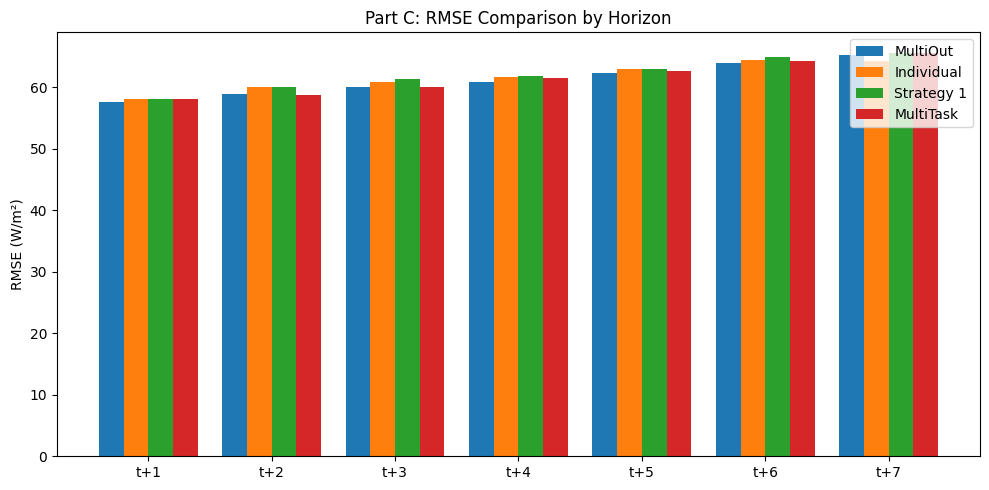

Part C complete.


In [5]:
# ══════════════════════════════════════════════════════════════
# PART C: Individual Models & Transfer Learning
# ══════════════════════════════════════════════════════════════
print("\n" + "="*60 + "\nPart C: Individual Models & Transfer Learning\n" + "="*60)

# Item 11: 7 independent single-output models
print("\n▶ Item 11: Seven individual single-output models")
indiv_rmse, indiv_mae, indiv_time, indiv_models = [], [], [], []
for h in range(HORIZONS):
    ltr_h = make_loader(Xtr, Ytr[:, h:h+1], shuffle=True)
    lva_h = make_loader(Xva, Yva[:, h:h+1])
    torch.manual_seed(42)
    m = SingleOutputMLP().to(DEVICE)
    _, _, elapsed = train_model(m, ltr_h, lva_h, nn.MSELoss())
    m.eval()
    with torch.no_grad():
        p = m(torch.tensor(Xte).to(DEVICE)).cpu().numpy()
    r = float(np.sqrt(np.mean((p - Yte[:, h:h+1])**2)))
    a = float(np.mean(np.abs(p - Yte[:, h:h+1])))
    indiv_rmse.append(r); indiv_mae.append(a); indiv_time.append(elapsed)
    indiv_models.append(m)
    torch.save(m.state_dict(), f"model_indiv_t{h+1}.pt")
    print(f"  t+{h+1}: RMSE={r:.3f}  MAE={a:.3f}  time={elapsed:.1f}s")

# Strategy 1: Sequential fine-tuning (t+1 weights → t+2 → … → t+7)
print("\n▶ Strategy 1: Sequential Fine-tuning")
s1_rmse, s1_mae, s1_time, s1_models = [], [], [], []
base_state = indiv_models[0].state_dict()
for h in range(HORIZONS):
    ltr_h = make_loader(Xtr, Ytr[:, h:h+1], shuffle=True)
    lva_h = make_loader(Xva, Yva[:, h:h+1])
    torch.manual_seed(42)
    m = SingleOutputMLP().to(DEVICE)
    m.load_state_dict(base_state)
    _, _, elapsed = train_model(m, ltr_h, lva_h, nn.MSELoss(), lr=1e-4, max_epochs=100, patience=15)
    m.eval()
    with torch.no_grad():
        p = m(torch.tensor(Xte).to(DEVICE)).cpu().numpy()
    r = float(np.sqrt(np.mean((p - Yte[:, h:h+1])**2)))
    a = float(np.mean(np.abs(p - Yte[:, h:h+1])))
    s1_rmse.append(r); s1_mae.append(a); s1_time.append(elapsed)
    s1_models.append(m)
    base_state = m.state_dict()
    torch.save(m.state_dict(), f"model_strategy1_t{h+1}.pt")
    print(f"  t+{h+1}: RMSE={r:.3f}  MAE={a:.3f}  time={elapsed:.1f}s")
torch.save(s1_models[-1].state_dict(), "model_strategy1_final.pt")

# Strategy 2: Feature extraction – freeze all except final layer, t+1 → t+7
print("\n▶ Strategy 2: Feature Extraction (t+1 → t+7)")
s2_model = SingleOutputMLP().to(DEVICE)
s2_model.load_state_dict(indiv_models[0].state_dict())
for name_p, param in s2_model.named_parameters():
    if "net.6" not in name_p:     # freeze everything except the last Linear
        param.requires_grad = False
ltr7 = make_loader(Xtr, Ytr[:, 6:7], shuffle=True)
lva7 = make_loader(Xva, Yva[:, 6:7])
train_model(s2_model, ltr7, lva7, nn.MSELoss(), lr=1e-4, max_epochs=100, patience=15)
s2_model.eval()
with torch.no_grad():
    p7 = s2_model(torch.tensor(Xte).to(DEVICE)).cpu().numpy()
s2_rmse = float(np.sqrt(np.mean((p7 - Yte[:, 6:7])**2)))
s2_mae  = float(np.mean(np.abs(p7 - Yte[:, 6:7])))
print(f"  t+7: RMSE={s2_rmse:.3f}  MAE={s2_mae:.3f}  (feature extraction only, t+7 reported)")
torch.save(s2_model.state_dict(), "model_strategy2.pt")

# Strategy 3: Multi-task learning with separate per-horizon heads
print("\n▶ Strategy 3: Multi-task Learning")
torch.manual_seed(42)
mt_model = MultiTaskMLP().to(DEVICE)
_, _, mt_time = train_model(mt_model, train_loader, val_loader, nn.MSELoss())
(mt_rmse, mt_mae, *_), mt_pred = evaluate(mt_model, Xte, Yte, return_pred=True)
print_metrics(mt_rmse, mt_mae)
torch.save(mt_model.state_dict(), "model_strategy3_multitask.pt")

# Comparison table
multiout_rmse = partB_results["WeightedMSE"][0]
multiout_mae  = partB_results["WeightedMSE"][1]
print("\nPart C RMSE Comparison:")
print(f"  {'Horizon':>8} {'MultiOut':>10} {'Indiv':>10} {'Strat1':>10} {'MultiTask':>10}")
for h in range(HORIZONS):
    print(f"  t+{h+1}      {multiout_rmse[h]:10.4f} {indiv_rmse[h]:10.4f} "
          f"{s1_rmse[h]:10.4f} {mt_rmse[h]:10.4f}")

# Training time comparison
print("\nWall-clock time per horizon (seconds):")
print(f"  {'Horizon':>8} {'Indiv':>8} {'Strat1':>8}")
for h in range(HORIZONS):
    print(f"  t+{h+1}      {indiv_time[h]:8.1f} {s1_time[h]:8.1f}")
print(f"  MultiTask total: {mt_time:.1f}s  MultiOut total: {partB_hist['WeightedMSE'][0].__len__()}-epoch run")

# RMSE grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(HORIZONS); w = 0.2
ax.bar(x-1.5*w, multiout_rmse,  w, label="MultiOut")
ax.bar(x-0.5*w, indiv_rmse,     w, label="Individual")
ax.bar(x+0.5*w, s1_rmse,        w, label="Strategy 1")
ax.bar(x+1.5*w, mt_rmse,        w, label="MultiTask")
ax.set_title("Part C: RMSE Comparison by Horizon")
ax.set_xticks(x); ax.set_xticklabels([f"t+{h}" for h in range(1, 8)])
ax.set_ylabel("RMSE (W/m²)"); ax.legend()
plt.tight_layout(); plt.savefig("partC_rmse.png", dpi=120); plt.show()
print("Part C complete.")





Part D: Advanced Techniques

▶ Item 14: MC Dropout (T=50 forward passes)
  Early stop @ epoch 69, best val: 3826.2403
  Done, 17.6s
MC Dropout metrics:
         RMSE     MAE
t+1   58.1322  45.9429
t+2   58.8470  46.0723
t+3   59.4925  46.6085
t+4   60.7085  47.4137
t+5   61.9864  48.2286
t+6   63.6812  49.5696
t+7   65.2976  50.9208
Macro  61.1636  47.8224


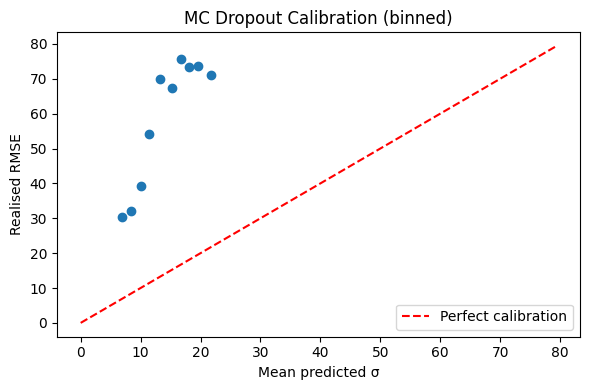

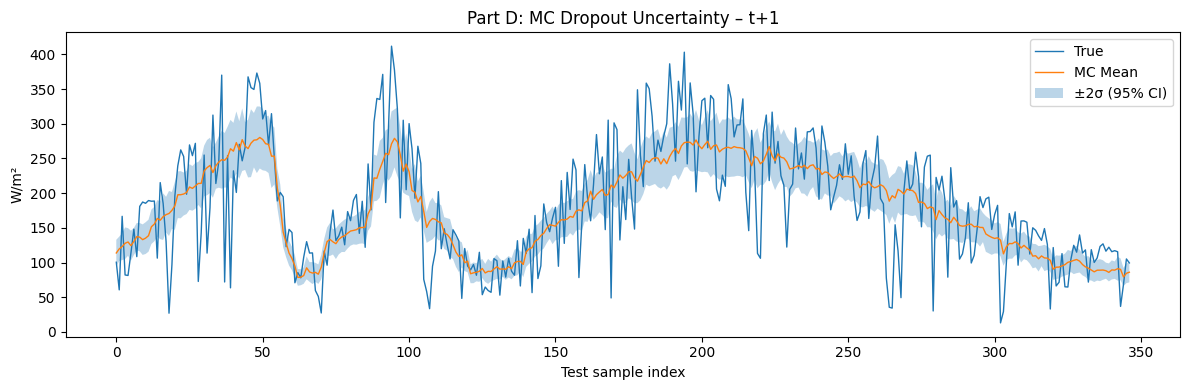

Calibration: fraction within ±2σ per horizon: t+1=32.3%  t+2=32.3%  t+3=33.1%  t+4=31.4%  t+5=30.8%  t+6=29.7%  t+7=27.7%

▶ Item 15: Attention Mechanism
  Early stop @ epoch 80, best val: 3896.3092
  Done, 37.0s
Attention model metrics:
         RMSE     MAE
t+1   57.8077  45.3610
t+2   58.4653  45.6144
t+3   59.8354  47.1417
t+4   60.8783  47.3686
t+5   62.9112  48.9158
t+6   64.5575  49.6866
t+7   66.3774  50.8156
Macro  61.5475  47.8434


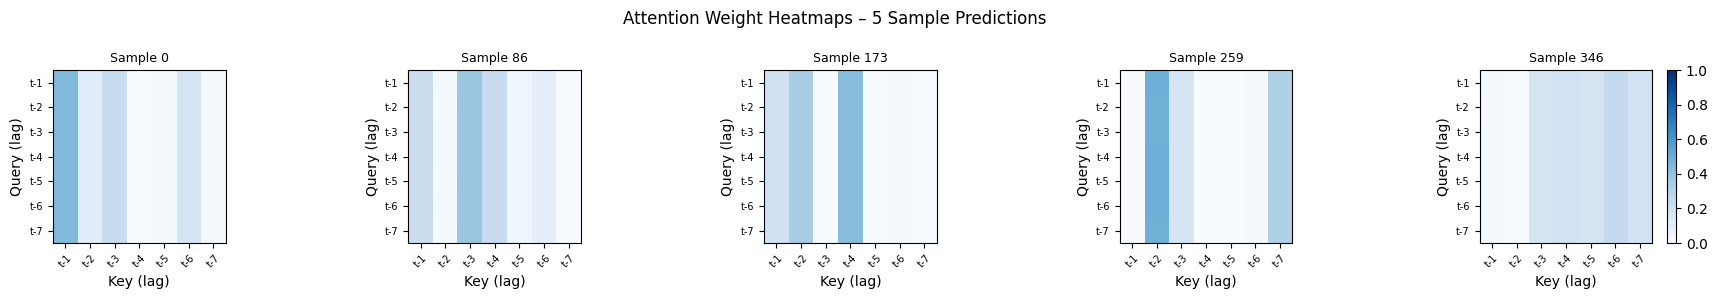


▶ Item 16: Ablation Study (attention model as baseline)
  Baseline (full attention): RMSE=61.5475  MAE=47.8434
  Early stop @ epoch 101, best val: 4217.3298
  Done, 49.1s
  No Fourier     : RMSE=69.6844  MAE=53.6031  (ΔRMSE=+8.1368)
  Early stop @ epoch 80, best val: 3892.2136
  Done, 38.3s
  No Rolling     : RMSE=61.6832  MAE=47.9189  (ΔRMSE=+0.1357)
  Early stop @ epoch 56, best val: 3824.9439
  Done, 13.9s
  No Lags        : RMSE=61.2314  MAE=47.6611  (ΔRMSE=-0.3162)
  Early stop @ epoch 69, best val: 3826.2403
  Done, 17.0s
  No Attention   : RMSE=61.1434  MAE=47.8022  (ΔRMSE=-0.4041)


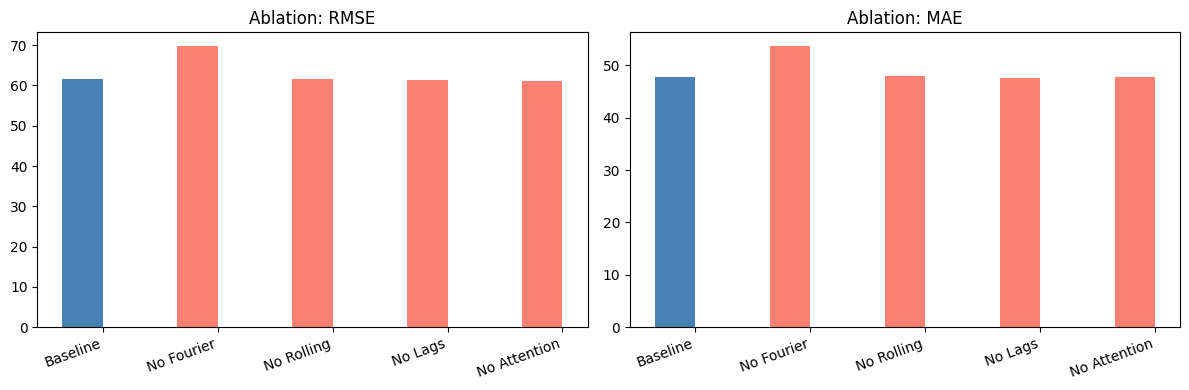

Part D complete.


In [6]:
# ══════════════════════════════════════════════════════════════
# PART D: Advanced Techniques
# ══════════════════════════════════════════════════════════════
print("\n" + "="*60 + "\nPart D: Advanced Techniques\n" + "="*60)

# ── 14. MC Dropout ───────────────────────────────────────────
print("\n▶ Item 14: MC Dropout (T=50 forward passes)")
torch.manual_seed(42)
mc_model = MCDropoutMLP().to(DEVICE)
train_model(mc_model, train_loader, val_loader, nn.MSELoss())
mu_t, sig_t  = mc_model.mc_predict(Xte, T=50)
mu_np        = mu_t.numpy()
sig_np       = sig_t.numpy()
mc_rmse      = np.sqrt(np.mean((mu_np - Yte)**2, axis=0))
mc_mae       = np.mean(np.abs(mu_np - Yte), axis=0)
print("MC Dropout metrics:")
print_metrics(mc_rmse, mc_mae)
torch.save(mc_model.state_dict(), "model_partD_mc.pt")

# Calibration: binned predicted σ vs realised RMSE
flat_sig = sig_np.flatten(); flat_err = np.abs(mu_np - Yte).flatten()
n_bins   = 10
bin_edges = np.percentile(flat_sig, np.linspace(0, 100, n_bins + 1))
bin_ids   = np.clip(np.digitize(flat_sig, bin_edges[:-1]) - 1, 0, n_bins - 1)
bin_sig   = [flat_sig[bin_ids == i].mean()  for i in range(n_bins) if (bin_ids == i).sum() > 0]
bin_rmse  = [np.sqrt(np.mean(flat_err[bin_ids == i]**2)) for i in range(n_bins) if (bin_ids == i).sum() > 0]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(bin_sig, bin_rmse, zorder=3)
lim = max(max(bin_sig), max(bin_rmse)) * 1.05
ax.plot([0, lim], [0, lim], "r--", label="Perfect calibration")
ax.set_xlabel("Mean predicted σ"); ax.set_ylabel("Realised RMSE")
ax.set_title("MC Dropout Calibration (binned)"); ax.legend()
plt.tight_layout(); plt.savefig("partD_calibration.png", dpi=120); plt.show()

# Uncertainty visualisation (t+1)
fig, ax = plt.subplots(figsize=(12, 4))
idx = np.arange(len(mu_np))
ax.plot(idx, Yte[:, 0], lw=1, label="True")
ax.plot(idx, mu_np[:, 0], lw=1, label="MC Mean")
ax.fill_between(idx, mu_np[:, 0] - 2*sig_np[:, 0], mu_np[:, 0] + 2*sig_np[:, 0],
                alpha=0.3, label="±2σ (95% CI)")
ax.set_title("Part D: MC Dropout Uncertainty – t+1")
ax.set_xlabel("Test sample index"); ax.set_ylabel("W/m²"); ax.legend()
plt.tight_layout(); plt.savefig("partD_uncertainty.png", dpi=120); plt.show()

within = np.mean(np.abs(mu_np - Yte) <= 2*sig_np, axis=0)
print(f"Calibration: fraction within ±2σ per horizon: "
      + "  ".join(f"t+{h+1}={within[h]*100:.1f}%" for h in range(HORIZONS)))

# ── 15. Attention Mechanism ──────────────────────────────────
print("\n▶ Item 15: Attention Mechanism")
torch.manual_seed(42)
attn_model = AttentionMLP().to(DEVICE)
train_model(attn_model, train_loader, val_loader, nn.MSELoss())
(attn_rmse, attn_mae, *_), attn_pred = evaluate(attn_model, Xte, Yte, return_pred=True)
print("Attention model metrics:")
print_metrics(attn_rmse, attn_mae)
torch.save(attn_model.state_dict(), "model_partD_attention.pt")

# Attention heatmaps for 5 samples
sample_ids = np.linspace(0, len(Xte) - 1, 5, dtype=int)
fig, axes  = plt.subplots(1, 5, figsize=(18, 3))
fig.suptitle("Attention Weight Heatmaps – 5 Sample Predictions")
attn_model.eval()
for ax, sid in zip(axes, sample_ids):
    x_s = torch.tensor(Xte[sid:sid+1]).to(DEVICE)
    with torch.no_grad():
        _, aw = attn_model(x_s, return_attn=True)
    im = ax.imshow(aw[0].cpu().numpy(), vmin=0, vmax=1, cmap="Blues")
    ax.set_title(f"Sample {sid}", fontsize=9)
    ax.set_xticks(range(7)); ax.set_yticks(range(7))
    ax.set_xticklabels([f"t-{k}" for k in range(1, 8)], rotation=45, fontsize=7)
    ax.set_yticklabels([f"t-{k}" for k in range(1, 8)], fontsize=7)
    ax.set_xlabel("Key (lag)"); ax.set_ylabel("Query (lag)")
plt.colorbar(im, ax=axes[-1])
plt.tight_layout(); plt.savefig("partD_attention_heatmap.png", dpi=120); plt.show()

# ── 16. Ablation Study ───────────────────────────────────────
print("\n▶ Item 16: Ablation Study (attention model as baseline)")

base_rmse_ab = attn_rmse.mean()
base_mae_ab  = attn_mae.mean()
print(f"  Baseline (full attention): RMSE={base_rmse_ab:.4f}  MAE={base_mae_ab:.4f}")

def run_ablation(remove_set, tag):
    keep_non_lag = [c for c in NON_LAG_COLS if c not in remove_set]
    keep_lag     = [c for c in LAG_COLS     if c not in remove_set]
    feat_cols    = keep_non_lag + keep_lag       # non-lag always first
    feat_idx     = [FEATURE_COLS.index(c) for c in feat_cols]
    Xtr_ab = Xtr[:, feat_idx]; Xva_ab = Xva[:, feat_idx]; Xte_ab = Xte[:, feat_idx]
    ltr = make_loader(Xtr_ab, Ytr, shuffle=True)
    lva = make_loader(Xva_ab, Yva)
    torch.manual_seed(42)
    use_attn = (len(keep_lag) >= 2) and (tag != "no_attention")
    if use_attn:
        m = AttentionMLP(n_non_lag=len(keep_non_lag), n_lags=len(keep_lag),
                         dk=16, hidden=128, out_dim=HORIZONS).to(DEVICE)
    else:
        m = MultiOutputMLP(in_dim=len(feat_cols)).to(DEVICE)
    train_model(m, ltr, lva, nn.MSELoss())
    m.eval()
    with torch.no_grad():
        p = m(torch.tensor(Xte_ab).to(DEVICE)).cpu().numpy()
    rmse = np.sqrt(np.mean((p - Yte)**2, axis=0)).mean()
    mae  = np.mean(np.abs(p - Yte), axis=0).mean()
    return rmse, mae

ablation_cfg = {
    "No Fourier":    set(["day_sin", "day_cos"]),
    "No Rolling":    set(["solar_mean_7d", "solar_std_7d", "solar_min_7d", "solar_max_7d"]),
    "No Lags":       set(LAG_COLS),
    "No Attention":  set(),
}
ablation_results = {}
for label, remove_set in ablation_cfg.items():
    tag = label.lower().replace(" ", "_")
    r, m_ = run_ablation(remove_set, tag)
    ablation_results[label] = (r, m_)
    print(f"  {label:<15}: RMSE={r:.4f}  MAE={m_:.4f}  (ΔRMSE={r-base_rmse_ab:+.4f})")

# Ablation bar chart
labels  = ["Baseline"] + list(ablation_results.keys())
rmses   = [base_rmse_ab]  + [v[0] for v in ablation_results.values()]
maes    = [base_mae_ab]   + [v[1] for v in ablation_results.values()]
colors  = ["steelblue"] + ["salmon"] * 4
x = np.arange(len(labels)); bw = 0.35
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x - bw/2, rmses, bw, color=colors); axes[0].set_title("Ablation: RMSE")
axes[1].bar(x - bw/2, maes,  bw, color=colors); axes[1].set_title("Ablation: MAE")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, ha="right")
plt.tight_layout(); plt.savefig("partD_ablation.png", dpi=120); plt.show()
print("Part D complete.")





Part E: Statistical Analysis

▶ Item 17: Paired t-tests (per-day mean MAE across 7 horizons)
  MultiOut vs Individual
    t= -3.3617  p=8.6127e-04  95% CI=(-0.7963, -0.2085)
  Attention vs MultiOut
    t=  0.8616  p=3.8949e-01  95% CI=(-0.2314, 0.5921)
  MultiOut vs MultiTask
    t= -3.9346  p=1.0073e-04  95% CI=(-0.5429, -0.1810)

▶ Item 18: Error Analysis


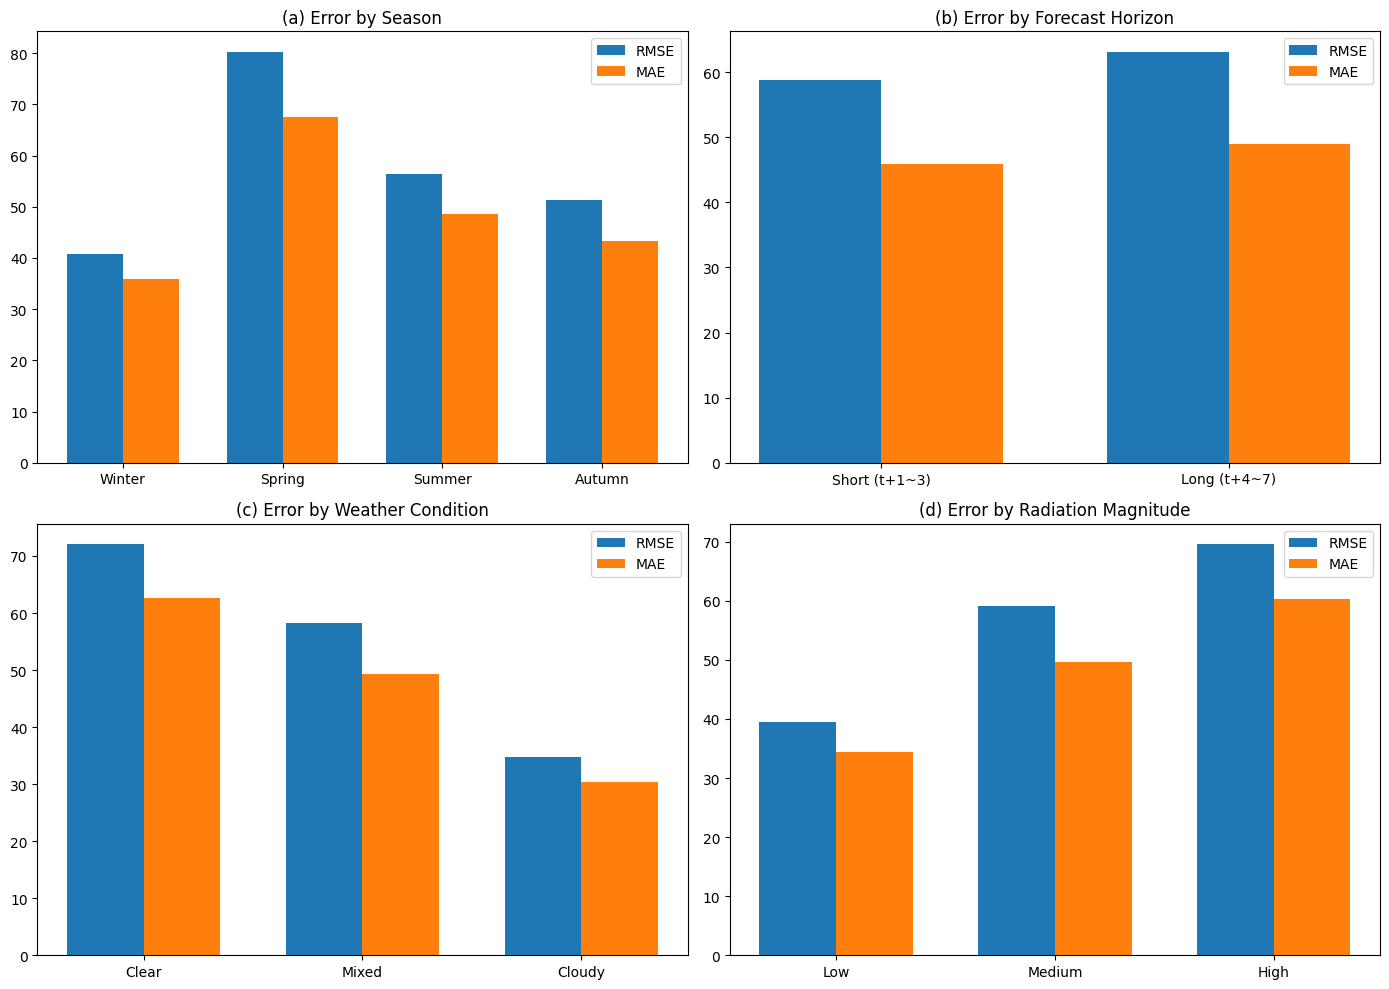

Part E complete.


In [7]:
# ══════════════════════════════════════════════════════════════
# PART E: Statistical Analysis and Discussion
# ══════════════════════════════════════════════════════════════
print("\n" + "="*60 + "\nPart E: Statistical Analysis\n" + "="*60)

# Reconstruct per-model predictions on test set
(_, _, _, _), multiout_pred = evaluate(partB_models["WeightedMSE"], Xte, Yte, return_pred=True)

indiv_pred = np.zeros_like(Yte)
for h, m in enumerate(indiv_models):
    m.eval()
    with torch.no_grad():
        indiv_pred[:, h] = m(torch.tensor(Xte).to(DEVICE)).cpu().numpy().squeeze()

# attn_pred and mt_pred already computed above

# Per-day MAE (averaged across 7 horizons)
day_mae = {
    "multiout": np.mean(np.abs(multiout_pred - Yte), axis=1),
    "indiv":    np.mean(np.abs(indiv_pred    - Yte), axis=1),
    "attn":     np.mean(np.abs(attn_pred     - Yte), axis=1),
    "multitask":np.mean(np.abs(mt_pred       - Yte), axis=1),
}

# ── 17. Paired t-tests ───────────────────────────────────────
print("\n▶ Item 17: Paired t-tests (per-day mean MAE across 7 horizons)")

def paired_ttest(a, b, label):
    t_stat, p_val = stats.ttest_rel(a, b)
    d = a - b; n = len(d)
    ci = stats.t.interval(0.95, df=n-1, loc=d.mean(), scale=stats.sem(d))
    print(f"  {label}")
    print(f"    t={t_stat:8.4f}  p={p_val:.4e}  95% CI=({ci[0]:.4f}, {ci[1]:.4f})")
    return t_stat, p_val, ci

paired_ttest(day_mae["multiout"], day_mae["indiv"],     "MultiOut vs Individual")
paired_ttest(day_mae["attn"],     day_mae["multiout"],  "Attention vs MultiOut")
paired_ttest(day_mae["multiout"], day_mae["multitask"], "MultiOut vs MultiTask")

# ── 18. Error Analysis ───────────────────────────────────────
print("\n▶ Item 18: Error Analysis")

pred_ea    = multiout_pred
true_ea    = Yte
test_dates = test_df["TIMESTAMP"].values

per_day_rmse = np.sqrt(np.mean((pred_ea - true_ea)**2, axis=1))
per_day_mae  = np.mean(np.abs(pred_ea - true_ea), axis=1)
day_mean_true = true_ea.mean(axis=1)

test_months = pd.DatetimeIndex(test_dates).month

def month_to_season(m):
    return ("Winter" if m in [12, 1, 2] else
            "Spring" if m in [3, 4, 5]  else
            "Summer" if m in [6, 7, 8]  else "Autumn")

seasons = np.array([month_to_season(m) for m in test_months])
season_order = ["Winter", "Spring", "Summer", "Autumn"]

q25_train = np.percentile(Ytr, 25); q75_train = np.percentile(Ytr, 75)
t33_train = np.percentile(Ytr, 33); t67_train = np.percentile(Ytr, 67)

weather = np.where(day_mean_true > q75_train, "Clear",
          np.where(day_mean_true < q25_train, "Cloudy", "Mixed"))
magnitude = np.where(day_mean_true > t67_train, "High",
            np.where(day_mean_true < t33_train, "Low", "Medium"))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
bw = 0.35

def bar_pair(ax, labels, rmse_vals, mae_vals, title):
    x = np.arange(len(labels))
    ax.bar(x - bw/2, rmse_vals, bw, label="RMSE")
    ax.bar(x + bw/2, mae_vals,  bw, label="MAE")
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_title(title); ax.legend()

# (a) Seasonal
bar_pair(axes[0, 0], season_order,
         [per_day_rmse[seasons==s].mean() for s in season_order],
         [per_day_mae[seasons==s].mean()  for s in season_order],
         "(a) Error by Season")

# (b) Short vs long horizon
bar_pair(axes[0, 1],
         ["Short (t+1~3)", "Long (t+4~7)"],
         [np.sqrt(np.mean((pred_ea[:,:3]-true_ea[:,:3])**2)),
          np.sqrt(np.mean((pred_ea[:,3:]-true_ea[:,3:])**2))],
         [np.mean(np.abs(pred_ea[:,:3]-true_ea[:,:3])),
          np.mean(np.abs(pred_ea[:,3:]-true_ea[:,3:]))],
         "(b) Error by Forecast Horizon")

# (c) Weather condition
wx_order = ["Clear", "Mixed", "Cloudy"]
bar_pair(axes[1, 0], wx_order,
         [per_day_rmse[weather==w].mean() for w in wx_order],
         [per_day_mae[weather==w].mean()  for w in wx_order],
         "(c) Error by Weather Condition")

# (d) Magnitude tercile
mag_order = ["Low", "Medium", "High"]
bar_pair(axes[1, 1], mag_order,
         [per_day_rmse[magnitude==m].mean() for m in mag_order],
         [per_day_mae[magnitude==m].mean()  for m in mag_order],
         "(d) Error by Radiation Magnitude")

plt.tight_layout(); plt.savefig("partE_error_analysis.png", dpi=120); plt.show()
print("Part E complete.")





▶ Verifying evaluation cell on test set (2011–2013)...

Evaluation on: H:\CLASS\9414\ass1\COMP9414_Assignment_1_datasets\datasets
Samples: 5549

  Model                       Macro RMSE  Macro MAE
  PartB_WeightedMSE              57.6131    44.1965
  PartB_PseudoHuber              58.2668    43.6380
  PartB_QuantileLoss             78.3256    53.8185
  Individual                     57.3400    44.2801
  Strategy1                      58.6447    45.2154
  Strategy2_t7                   60.8296    46.5401
  MultiTask                      57.8080    44.5628
  MCDropout                      57.8107    44.6072
  Attention                      58.2210    44.6424


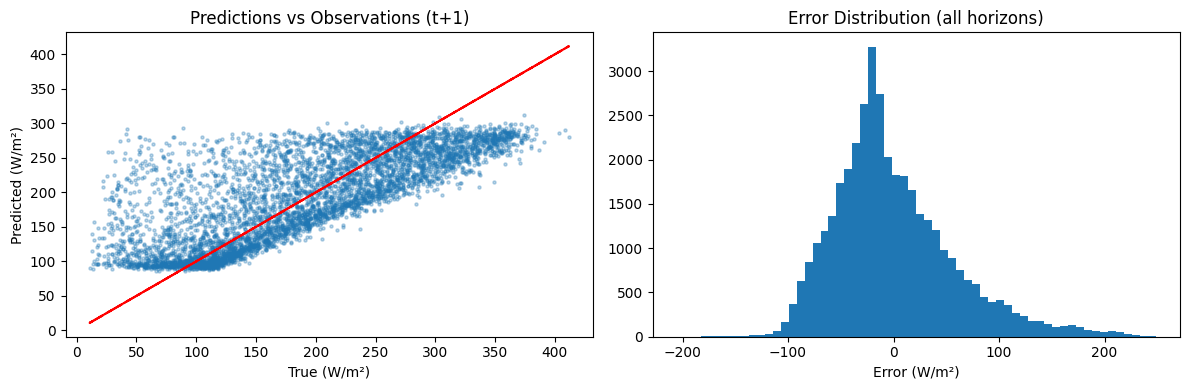


All parts complete. Ready for submission.
Files to include in z5565492_assignment1.zip:
  eval_predictions.png
  model_indiv_t1.pt
  model_indiv_t2.pt
  model_indiv_t3.pt
  model_indiv_t4.pt
  model_indiv_t5.pt
  model_indiv_t6.pt
  model_indiv_t7.pt
  model_partB_PseudoHuber.pt
  model_partB_QuantileLoss.pt
  model_partB_WeightedMSE.pt
  model_partD_attention.pt
  model_partD_mc.pt
  model_strategy1_final.pt
  model_strategy1_t1.pt
  model_strategy1_t2.pt
  model_strategy1_t3.pt
  model_strategy1_t4.pt
  model_strategy1_t5.pt
  model_strategy1_t6.pt
  model_strategy1_t7.pt
  model_strategy2.pt
  model_strategy3_multitask.pt
  partA_distribution.png
  partA_timeseries.png
  partB_loss.png
  partB_metrics.png
  partC_rmse.png
  partD_ablation.png
  partD_attention_heatmap.png
  partD_calibration.png
  partD_uncertainty.png
  partE_error_analysis.png
  scaler.pkl
  z5565492_assignment1.ipynb


In [8]:
# ══════════════════════════════════════════════════════════════
# EVALUATION CELL – Hidden Dataset (2014–2019)
# Run this cell during the discussion session with hidden data.
# Verified below on test set (2011–2013) before submission.
# ══════════════════════════════════════════════════════════════

def preprocess_hidden(data_dir):
    files = sorted([f for f in os.listdir(data_dir) if f.endswith(".csv")])
    dfs   = [pd.read_csv(os.path.join(data_dir, f), parse_dates=["date"]) for f in files]
    df    = pd.concat(dfs, ignore_index=True).sort_values("date").reset_index(drop=True)
    df.rename(columns={"date": "TIMESTAMP", "solar_t": "SolarRadiation",
                        "bad_quality": "QualityFlag"}, inplace=True)
    df = df[df["QualityFlag"] == 0].reset_index(drop=True)

    df["day_of_year"] = df["TIMESTAMP"].dt.dayofyear
    leap = df["TIMESTAMP"].dt.year.apply(
        lambda y: 366 if (y%4==0 and (y%100!=0 or y%400==0)) else 365)
    df["day_sin"] = np.sin(2*np.pi*df["day_of_year"]/leap)
    df["day_cos"] = np.cos(2*np.pi*df["day_of_year"]/leap)
    sr = df["SolarRadiation"]
    df["solar_mean_7d"] = sr.rolling(7, min_periods=7).mean()
    df["solar_std_7d"]  = sr.rolling(7, min_periods=7).std(ddof=1)
    df["solar_min_7d"]  = sr.rolling(7, min_periods=7).min()
    df["solar_max_7d"]  = sr.rolling(7, min_periods=7).max()
    for k in range(1, 8): df[f"solar_lag_{k}"] = sr.shift(k)
    for h in range(1, 8): df[f"solar_t+{h}"]   = sr.shift(-h)
    df = df.dropna(subset=FEATURE_COLS + TARGET_COLS).iloc[7:].reset_index(drop=True)

    with open("scaler.pkl", "rb") as f:
        sc = pickle.load(f)
    X = sc.transform(df[FEATURE_COLS].values).astype(np.float32)
    Y = df[TARGET_COLS].values.astype(np.float32)
    return X, Y, df

def run_evaluation(data_dir):
    print(f"\n{'='*60}\nEvaluation on: {data_dir}\n{'='*60}")
    X_h, Y_h, _ = preprocess_hidden(data_dir)
    print(f"Samples: {len(X_h)}")

    def load_eval_multi(cls, path, **kwargs):
        m = cls(**kwargs).to(DEVICE) if kwargs else cls().to(DEVICE)
        m.load_state_dict(torch.load(path, map_location=DEVICE))
        m.eval()
        with torch.no_grad():
            return m(torch.tensor(X_h).to(DEVICE)).cpu().numpy()

    results = {}
    print(f"\n  {'Model':<25} {'Macro RMSE':>12} {'Macro MAE':>10}")

    for name in ["WeightedMSE", "PseudoHuber", "QuantileLoss"]:
        p = load_eval_multi(MultiOutputMLP, f"model_partB_{name}.pt")
        r, a = np.sqrt(np.mean((p-Y_h)**2)), np.mean(np.abs(p-Y_h))
        results[f"PartB_{name}"] = (r, a)
        print(f"  {'PartB_'+name:<25} {r:12.4f} {a:10.4f}")

    indiv_p = np.zeros_like(Y_h)
    for h in range(HORIZONS):
        m = SingleOutputMLP().to(DEVICE)
        m.load_state_dict(torch.load(f"model_indiv_t{h+1}.pt", map_location=DEVICE))
        m.eval()
        with torch.no_grad():
            indiv_p[:, h] = m(torch.tensor(X_h).to(DEVICE)).cpu().numpy().squeeze()
    r, a = np.sqrt(np.mean((indiv_p-Y_h)**2)), np.mean(np.abs(indiv_p-Y_h))
    results["Individual"] = (r, a); print(f"  {'Individual':<25} {r:12.4f} {a:10.4f}")

    for tag, cls, path, kw in [
        ("Strategy1",  SingleOutputMLP, "model_strategy1_final.pt", {}),
        ("Strategy2_t7", SingleOutputMLP, "model_strategy2.pt",     {}),
        ("MultiTask",  MultiTaskMLP,    "model_strategy3_multitask.pt", {}),
        ("MCDropout",  MCDropoutMLP,    "model_partD_mc.pt",        {}),
        ("Attention",  AttentionMLP,    "model_partD_attention.pt", {}),
    ]:
        try:
            p = load_eval_multi(cls, path, **kw)
            if p.shape[1] == 1:
                r = float(np.sqrt(np.mean((p - Y_h[:, 6:7])**2)))
                a = float(np.mean(np.abs(p - Y_h[:, 6:7])))
            else:
                r = float(np.sqrt(np.mean((p - Y_h)**2)))
                a = float(np.mean(np.abs(p - Y_h)))
            results[tag] = (r, a); print(f"  {tag:<25} {r:12.4f} {a:10.4f}")
        except Exception as e:
            print(f"  {tag:<25} ERROR: {e}")

    # Predictions vs observations and error distribution
    p_best = load_eval_multi(MultiOutputMLP, "model_partB_WeightedMSE.pt")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(Y_h[:, 0], p_best[:, 0], alpha=0.3, s=5)
    axes[0].plot([Y_h[:,0].min(), Y_h[:,0].max()]*2, [Y_h[:,0].min(), Y_h[:,0].max()]*2,
                 "r--")
    axes[0].set_title("Predictions vs Observations (t+1)")
    axes[0].set_xlabel("True (W/m²)"); axes[0].set_ylabel("Predicted (W/m²)")
    axes[1].hist((p_best - Y_h).flatten(), bins=60)
    axes[1].set_title("Error Distribution (all horizons)")
    axes[1].set_xlabel("Error (W/m²)")
    plt.tight_layout(); plt.savefig("eval_predictions.png", dpi=120); plt.show()
    return results

# Verify evaluation cell on test set before submission
print("\n▶ Verifying evaluation cell on test set (2011–2013)...")
run_evaluation(DATA_DIR)

print("\nAll parts complete. Ready for submission.")
print("Files to include in z5565492_assignment1.zip:")
for f in sorted(os.listdir(".")):
    if f.endswith((".pt", ".pkl", ".png", ".ipynb", ".py")):
        print(f"  {f}")


Evaluation on: H:\CLASS\9414\ass1\COMP9414_Assignment_1_HiddenDataset\HiddenDataset
Samples: 2012

  Model                       Macro RMSE  Macro MAE
  PartB_WeightedMSE              59.2352    45.2762
  PartB_PseudoHuber              59.7414    44.4308
  PartB_QuantileLoss             79.6442    54.5429
  Individual                     59.3485    45.6463
  Strategy1                      59.7182    46.0167
  Strategy2_t7                   61.0975    46.7338
  MultiTask                      59.3374    45.5608
  MCDropout                      59.4356    45.7230
  Attention                      59.6743    45.6015


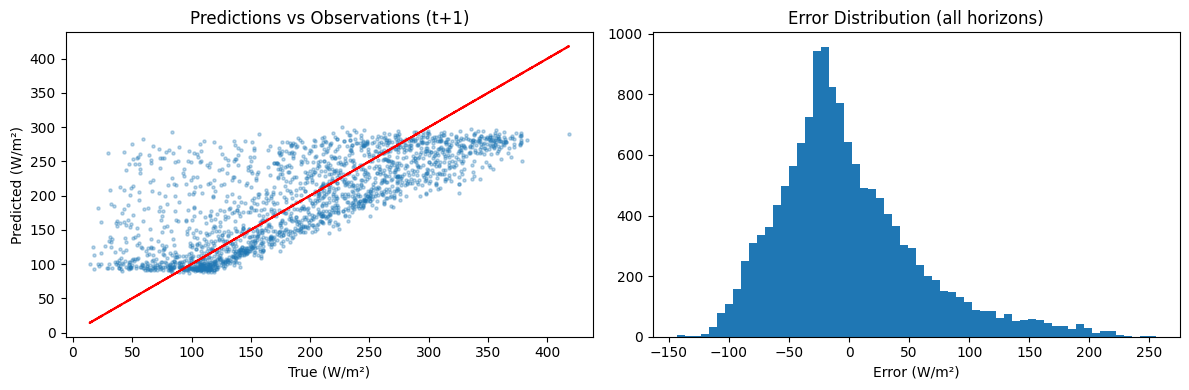

In [9]:
HIDDEN_DIR = r"H:\CLASS\9414\ass1\COMP9414_Assignment_1_HiddenDataset\HiddenDataset"
hidden_results = run_evaluation(HIDDEN_DIR)